In [1]:
import pathlib

import pandas as pd
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import plotting
from el_hd_plasticity.connectomics import synapse_distance as sd

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)
syndist_folder = figfolder / 'syn_distances'


## Pre- and postsynaptic distances side by side, for every ER subtype

Four distances of the same ER->EPG synapses, two measured along the presynaptic ER neuron and two along the postsynaptic EPG neuron.
One figure per ER subtype: the four histograms stacked, then an ECDF of all four.

| | measured along | from | to the nearest |
|---|---|---|---|
| **pre: other EB column** | the ER axon | each ER->EPG presynapse | ER->EPG presynapse onto a *different EB wedge* (`epg_instance_synapse_distance.ipynb`) |
| **pre: EL input** | the ER axon | each ER->EPG presynapse | EL->ER input synapse (`synapse_distance.ipynb`) |
| **post: ER of other hemisphere** | the EPG dendrite | each ER->EPG postsynapse | ER->EPG postsynapse from an ER neuron of the *other hemisphere* (`epg_postsynapse_distance.ipynb`) |
| **post: EL input** | the EPG dendrite | each ER->EPG postsynapse | EL->EPG input synapse |

None of the four is length-limited, so every synapse with a partner on its neuron gets a distance and the four panels are directly
comparable. The EL distances therefore come from the ``_uncapped`` pickles rather than the ones behind `synapse_distance.ipynb`, which
keep the published cutoffs (candidates within 10 microns Euclidean, paths up to 15 microns). All panels share the 0-16 micron scale and
bins, so a type whose distances run longer than that has its tail off the right edge; the ECDF curves show how much.

In [2]:
SOURCES = ('pre_column', 'pre_el', 'post_hemisphere', 'post_el')
LABELS = {'pre_column': 'pre: nearest ER->EPG presynapse of another EB wedge',
          'pre_el': 'pre: nearest EL input on the ER neuron',
          'post_hemisphere': 'post: nearest ER->EPG input from the other hemisphere',
          'post_el': 'post: nearest EL input on the EPG neuron'}
COLORS = (plt.cm.Greys(.8), plt.cm.Greys(.5), plt.cm.cool(.7), plt.cm.autumn(.3))

distance_df = pd.concat([
    sd.load_instance_distance_table(syndist_folder, sd.ER_TYPES, name='pre_column'),
    sd.load_distance_table(syndist_folder, sd.ER_TYPES, ('el_post',), names=['pre_el'],
                           filename='{type}_syn_distances_uncapped.pkl'),
    sd.load_instance_distance_table(syndist_folder, sd.ER_TYPES, name='post_hemisphere',
                                    filename='{type}_epg_post_hemisphere_distances.pkl'),
    sd.load_distance_table(syndist_folder, sd.ER_TYPES, ('el_post',), names=['post_el'],
                           filename='{type}_epg_post_el_distances.pkl'),
], ignore_index=True)

summary = distance_df.pivot_table(index='er', columns='source', values='distances', aggfunc='median')
print('median distance (microns)')
print(summary.loc[list(sd.ER_TYPES), list(SOURCES)].round(2))
print('\nfraction of synapses with no partner in range')
print(distance_df.pivot_table(index='er', columns='source', values='distances',
                              aggfunc=lambda d: d.isna().mean()).loc[list(sd.ER_TYPES), list(SOURCES)].round(2))


median distance (microns)
source  pre_column  pre_el  post_hemisphere  post_el
er                                                  
ER4d         13.62    2.01             1.23     3.78
ER4m          2.86    5.44             1.88     4.41
ER2_a         6.70    3.23             3.44     4.31
ER2_b         3.12    2.65             4.02     4.52
ER2_c         8.01    3.26             1.60     4.08
ER2_d         5.65    3.16             4.06     4.24
ER3w_b        1.18    2.70             1.69     5.19
ER3a_c        3.99    1.54             9.55     4.75
ER3p_a        0.92    1.47             1.15     5.31
ER3w_a        1.72    2.50             2.28     4.90
ER3a_b       27.74    1.95            20.25     5.51
ER3p_b        1.61    1.25             1.52     5.62
ER3d_c        6.06    2.64             2.11     6.44
ER3d_a        6.20    2.38             1.58     6.31
ER3d_d        6.78    3.30             2.11     7.02
ER3d_b        5.36    1.73             1.46     7.38
ER3a_a        8.00  

One figure per ER subtype.

In [3]:
for er_type in sd.ER_TYPES:
    fig, axs = plotting.plot_distance_stack(distance_df, (er_type,), SOURCES, labels=LABELS, colors=COLORS)
    axs[0].annotate(er_type, (0, 1.6), xycoords='axes fraction', fontsize=9, fontweight='bold')
    fig.savefig(figfolder / f'{er_type}_distance_stack.pdf', bbox_inches='tight')
    plt.close(fig)

print(f'{len(sd.ER_TYPES)} figures written to {figfolder}')


21 figures written to /media/mplitt/SSD_storage/fig_scratch/EL_connectomics


ER4d on its own, as the example shown in the other notebooks.

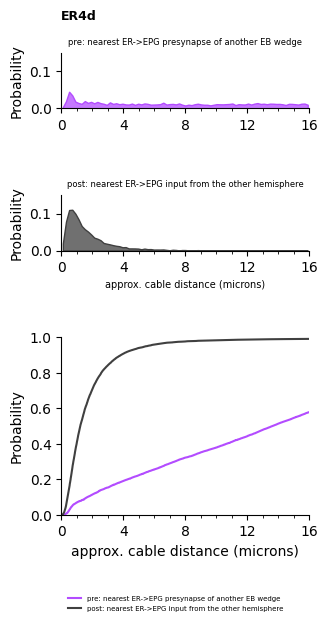

In [6]:
_SOURCES = ('pre_column', 'post_hemisphere')
_LABELS = {'pre_column': 'pre: nearest ER->EPG presynapse of another EB wedge',
          'pre_el': 'pre: nearest EL input on the ER neuron',
          'post_hemisphere': 'post: nearest ER->EPG input from the other hemisphere',
          'post_el': 'post: nearest EL input on the EPG neuron'}
_COLORS = (plt.cm.cool(.7), plt.cm.Greys(.8))

fig, axs = plotting.plot_distance_stack(distance_df, ('ER4d',), _SOURCES, labels=LABELS, colors=_COLORS)
axs[0].annotate('ER4d', (0, 1.6), xycoords='axes fraction', fontsize=9, fontweight='bold')
fig.savefig(figfolder / "pre_v_post_synapse_distance_ER4d.pdf")